In [1]:
import pandas as pd

url = "https://www.openml.org/data/get_csv/16826755/phpMYEkMl"
df = pd.read_csv(url)
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29,0,0,24160,211.3375,B5,S,2,?,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.55,C22 C26,S,11,?,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2,1,2,113781,151.55,C22 C26,S,?,?,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30,1,2,113781,151.55,C22 C26,S,?,135,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25,1,2,113781,151.55,C22 C26,S,?,?,"Montreal, PQ / Chesterville, ON"


In [2]:
df.tail(10)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
1299,3,0,"Yasbeck, Mr. Antoni",male,27,1,0,2659,14.4542,?,C,C,?,?
1300,3,1,"Yasbeck, Mrs. Antoni (Selini Alexander)",female,15,1,0,2659,14.4542,?,C,?,?,?
1301,3,0,"Youseff, Mr. Gerious",male,45.5,0,0,2628,7.225,?,C,?,312,?
1302,3,0,"Yousif, Mr. Wazli",male,?,0,0,2647,7.225,?,C,?,?,?
1303,3,0,"Yousseff, Mr. Gerious",male,?,0,0,2627,14.4583,?,C,?,?,?
1304,3,0,"Zabour, Miss. Hileni",female,14.5,1,0,2665,14.4542,?,C,?,328,?
1305,3,0,"Zabour, Miss. Thamine",female,?,1,0,2665,14.4542,?,C,?,?,?
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.5,0,0,2656,7.225,?,C,?,304,?
1307,3,0,"Zakarian, Mr. Ortin",male,27,0,0,2670,7.225,?,C,?,?,?
1308,3,0,"Zimmerman, Mr. Leo",male,29,0,0,315082,7.875,?,S,?,?,?


In [3]:
df.shape

(1309, 14)

In [4]:
df.describe()

,pclass,survived,sibsp,parch
count,1309.000000,1309.000000,1309.000000,1309.000000
mean,2.294882,0.381971,0.498854,0.385027
std,0.837836,0.486055,1.041658,0.865560
min,1.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,0.000000
50%,3.000000,0.000000,0.000000,0.000000
75%,3.000000,1.000000,1.000000,0.000000
max,3.000000,1.000000,8.000000,9.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   pclass     1309 non-null   int64
 1   survived   1309 non-null   int64
 2   name       1309 non-null   str  
 3   sex        1309 non-null   str  
 4   age        1309 non-null   str  
 5   sibsp      1309 non-null   int64
 6   parch      1309 non-null   int64
 7   ticket     1309 non-null   str  
 8   fare       1309 non-null   str  
 9   cabin      1309 non-null   str  
 10  embarked   1309 non-null   str  
 11  boat       1309 non-null   str  
 12  body       1309 non-null   str  
 13  home.dest  1309 non-null   str  
dtypes: int64(4), str(10)
memory usage: 143.3 KB


In [6]:
df.isnull().sum()

pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
ticket       0
fare         0
cabin        0
embarked     0
boat         0
body         0
home.dest    0
dtype: int64

Apart from a glance at the table, the nunique() method tells us that several data types were missrepresented.

In [7]:
df[['sex', 'age','ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest', 'sibsp', 'pclass']].nunique()

sex            2
age           99
ticket       929
fare         282
cabin        187
embarked       4
boat          28
body         122
home.dest    370
sibsp          7
pclass         3
dtype: int64

In [8]:
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')
df['body'] = pd.to_numeric(df['body'], errors='coerce')

In [9]:
def convert_to_numeric (df, num_cols):
    new_df = df.copy()
    new_df[num_cols] = new_df[num_cols].apply(pd.to_numeric, errors = 'coerce')
    return new_df

In [10]:
#num_cols = ['age', 'fare', 'body']
convert_to_numeric (df, num_cols= ['age', 'fare', 'body']).head(20)

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,?,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,?,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,?,NaN,"Montreal, PQ / Chesterville, ON"
5,1,1,"Anderson, Mr. Harry",male,48.0000,0,0,19952,26.5500,E12,S,3,NaN,"New York, NY"
6,1,1,"Andrews, Miss. Kornelia Theodosia",female,63.0000,1,0,13502,77.9583,D7,S,10,NaN,"Hudson, NY"
7,1,0,"Andrews, Mr. Thomas Jr",male,39.0000,0,0,112050,0.0000,A36,S,?,NaN,"Belfast, NI"
8,1,1,"Appleton, Mrs. Edward Dale (Charlotte Lamson)",female,53.0000,2,0,11769,51.4792,C101,S,D,NaN,"Bayside, Queens, NY"
9,1,0,"Artagaveytia, Mr. Ramon",male,71.0000,0,0,PC 17609,49.5042,?,C,?,22.0,"Montevideo, Uruguay"


In [11]:
df.describe(include='all')

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
count,1309.000000,1309.000000,1309,1309,1046.000000,1309.000000,1309.000000,1309,1308.000000,1309,1309,1309,121.000000,1309
unique,NaN,NaN,1307,2,NaN,NaN,NaN,929,NaN,187,4,28,NaN,370
top,NaN,NaN,"Connolly, Miss. Kate",male,NaN,NaN,NaN,CA. 2343,NaN,?,S,?,NaN,?
freq,NaN,NaN,2,843,NaN,NaN,NaN,11,NaN,1014,914,823,NaN,564
mean,2.294882,0.381971,NaN,NaN,29.881135,0.498854,0.385027,NaN,33.295479,NaN,NaN,NaN,160.809917,NaN
std,0.837836,0.486055,NaN,NaN,14.413500,1.041658,0.865560,NaN,51.758668,NaN,NaN,NaN,97.696922,NaN
min,1.000000,0.000000,NaN,NaN,0.166700,0.000000,0.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN
25%,2.000000,0.000000,NaN,NaN,21.000000,0.000000,0.000000,NaN,7.895800,NaN,NaN,NaN,72.000000,NaN
50%,3.000000,0.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,NaN,155.000000,NaN
75%,3.000000,1.000000,NaN,NaN,39.000000,1.000000,0.000000,NaN,31.275000,NaN,NaN,NaN,256.000000,NaN


            pclass  survived       age     sibsp     parch      fare      body
pclass    1.000000 -0.312469 -0.408106  0.060832  0.018322 -0.558629 -0.034642
survived -0.312469  1.000000 -0.055513 -0.027825  0.082660  0.244265       NaN
age      -0.408106 -0.055513  1.000000 -0.243699 -0.150917  0.178739  0.058809
sibsp     0.060832 -0.027825 -0.243699  1.000000  0.373587  0.160238 -0.099961
parch     0.018322  0.082660 -0.150917  0.373587  1.000000  0.221539  0.051099
fare     -0.558629  0.244265  0.178739  0.160238  0.221539  1.000000 -0.043110
body     -0.034642       NaN  0.058809 -0.099961  0.051099 -0.043110  1.000000


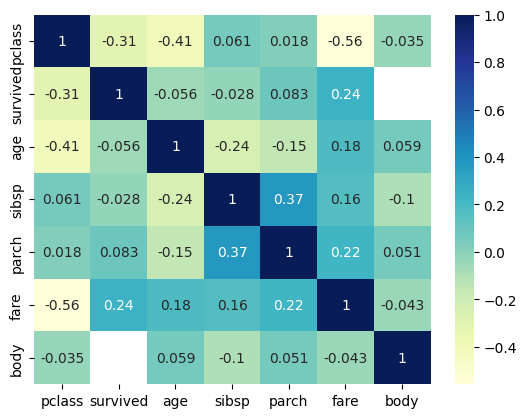

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

co_mtx = df.corr(numeric_only=True)
print (co_mtx)

sns.heatmap(co_mtx, cmap="YlGnBu", annot=True)

plt.show()

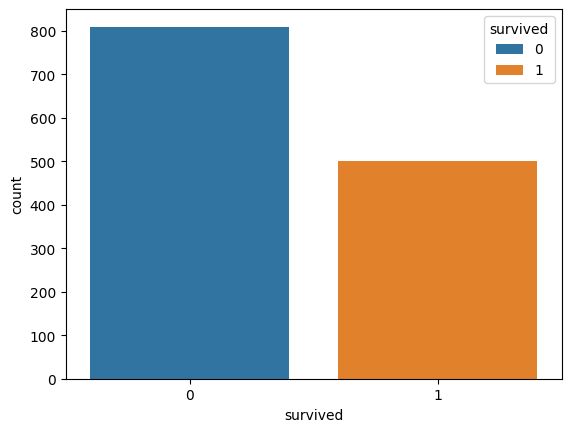

In [13]:
sns.countplot(df, x='survived', hue='survived')
plt.show()

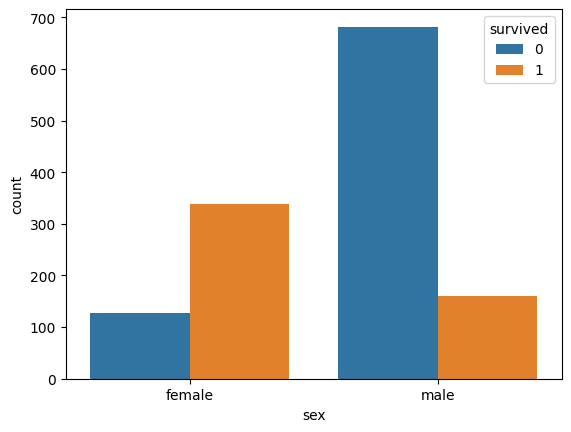

In [14]:
sns.countplot(df, x='sex', hue='survived')
plt.show()

<Axes: xlabel='pclass', ylabel='survived'>

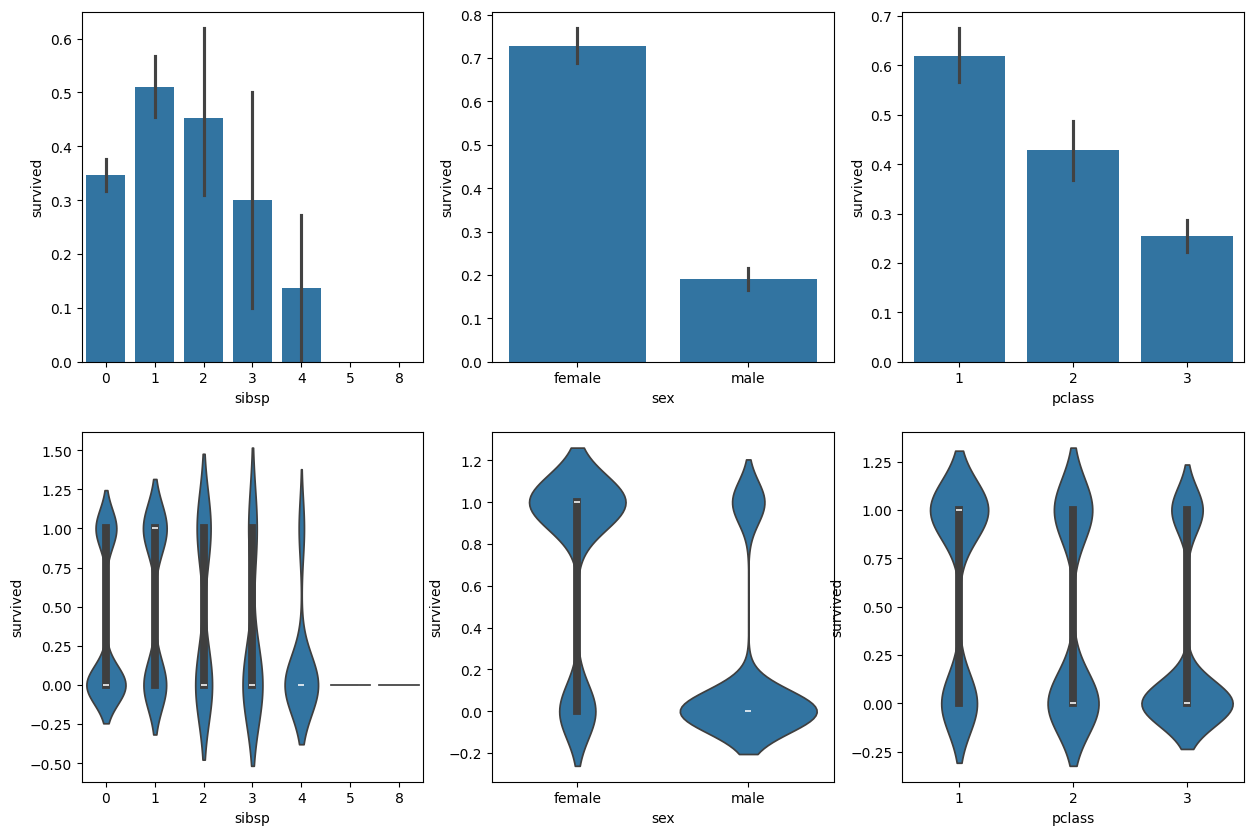

In [15]:
fig = plt.figure(figsize=(15,10))

ax1 = fig.add_subplot (2,3,1)
sns.barplot(data=df, x='sibsp', y='survived', ax = ax1)

ax2 = fig.add_subplot (2,3,2)
sns.barplot(data=df, x='sex', y='survived', ax = ax2)

ax3 = fig.add_subplot (2,3,3)
sns.barplot(data=df, x='pclass', y = 'survived', ax = ax3)

ax4 = fig.add_subplot(2,3,4)
sns.violinplot(data=df, x = 'sibsp', y = 'survived', ax = ax4)

ax5 = fig.add_subplot(2,3,5)
sns.violinplot (data=df, x = 'sex', y = 'survived', ax = ax5)

ax6 = fig.add_subplot(2,3,6)
sns.violinplot (data=df, x = 'pclass', y = 'survived', ax = ax6)

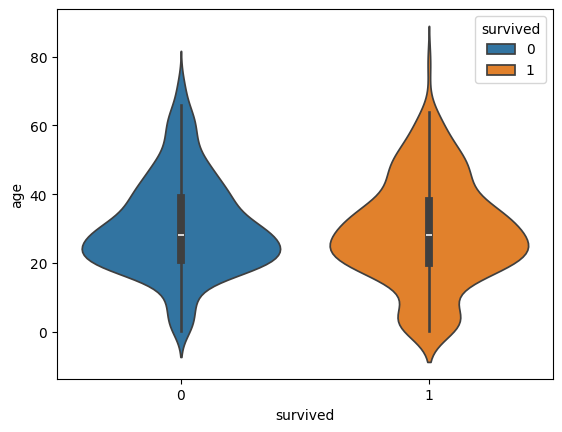

In [16]:
sns.violinplot(df, x= 'survived', y='age', hue = 'survived')
plt.show()

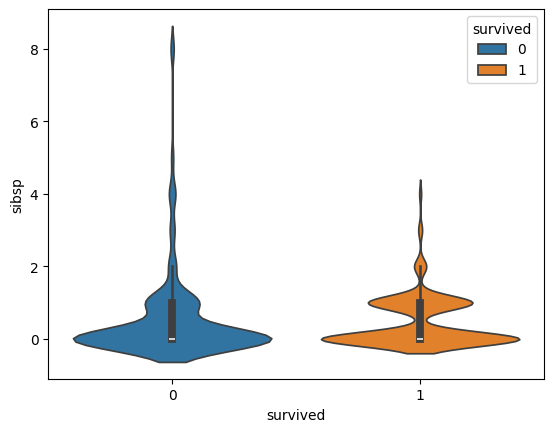

In [17]:
sns.violinplot(df, x= 'survived', y='sibsp', hue = 'survived')
plt.show()

DATA PREPROCESSING

In [18]:
df.duplicated().any()

np.False_

This would generally men there are no duplicates. But to be certain of t, we must examine certain features that are most likely to be unique but yet appear as duplicates and then compare them accross
different other parameters

In [19]:
df.duplicated(subset=['name']).any()

np.True_

In [20]:
duplicated_rows = df[df.duplicated(subset=['name'], keep= False)]
print(duplicated_rows)

     pclass  survived                  name     sex   age  sibsp  parch  \
725       3         1  Connolly, Miss. Kate  female  22.0      0      0   
726       3         0  Connolly, Miss. Kate  female  30.0      0      0   
924       3         0      Kelly, Mr. James    male  34.5      0      0   
925       3         0      Kelly, Mr. James    male  44.0      0      0   

     ticket    fare cabin embarked boat  body home.dest  
725  370373  7.7500     ?        Q   13   NaN   Ireland  
726  330972  7.6292     ?        Q    ?   NaN   Ireland  
924  330911  7.8292     ?        Q    ?  70.0         ?  
925  363592  8.0500     ?        S    ?   NaN         ?  


In [21]:
df.duplicated(subset=['ticket']).sum()

np.int64(380)

In [22]:
duplicated_ticket = df[df.duplicated(subset=['ticket'], keep= False)]
print(duplicated_ticket)

      pclass  survived                                             name  \
0          1         1                    Allen, Miss. Elisabeth Walton   
1          1         1                   Allison, Master. Hudson Trevor   
2          1         0                     Allison, Miss. Helen Loraine   
3          1         0             Allison, Mr. Hudson Joshua Creighton   
4          1         0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)   
...      ...       ...                                              ...   
1299       3         0                              Yasbeck, Mr. Antoni   
1300       3         1          Yasbeck, Mrs. Antoni (Selini Alexander)   
1303       3         0                            Yousseff, Mr. Gerious   
1304       3         0                             Zabour, Miss. Hileni   
1305       3         0                            Zabour, Miss. Thamine   

         sex      age  sibsp  parch  ticket      fare    cabin embarked boat  \
0     female  29.00

In [23]:
def remove_col (df, drop_col):
    df_1 = df.copy()
    df_1 = df_1.drop(drop_col,axis = 1)
    return df_1

In [24]:
#drop_col = df[['name','home.dest']]
df_drop = remove_col(df, drop_col=df[['name','home.dest', 'ticket', 'cabin', 'body', 'boat']])
df_drop.tail(10)

,pclass,survived,sex,age,sibsp,parch,fare,embarked
1299,3,0,male,27.0,1,0,14.4542,C
1300,3,1,female,15.0,1,0,14.4542,C
1301,3,0,male,45.5,0,0,7.2250,C
1302,3,0,male,NaN,0,0,7.2250,C
1303,3,0,male,NaN,0,0,14.4583,C
1304,3,0,female,14.5,1,0,14.4542,C
1305,3,0,female,NaN,1,0,14.4542,C
1306,3,0,male,26.5,0,0,7.2250,C
1307,3,0,male,27.0,0,0,7.2250,C
1308,3,0,male,29.0,0,0,7.8750,S


In [25]:
import numpy as np

def replace_val(df_drop):
    df_2 = df_drop.replace("?", np.nan, inplace=True)
    return df_2


In [26]:
df_replace = replace_val(df_drop)
df_replace.head(20)

,pclass,survived,sex,age,sibsp,parch,fare,embarked
0,1,1,female,29.0000,0,0,211.3375,S
1,1,1,male,0.9167,1,2,151.5500,S
2,1,0,female,2.0000,1,2,151.5500,S
3,1,0,male,30.0000,1,2,151.5500,S
4,1,0,female,25.0000,1,2,151.5500,S
5,1,1,male,48.0000,0,0,26.5500,S
6,1,1,female,63.0000,1,0,77.9583,S
7,1,0,male,39.0000,0,0,0.0000,S
8,1,1,female,53.0000,2,0,51.4792,S
9,1,0,male,71.0000,0,0,49.5042,C


In [27]:
df_replace.isnull().sum()

pclass        0
survived      0
sex           0
age         263
sibsp         0
parch         0
fare          1
embarked      2
dtype: int64

In [28]:
df_replace.nunique()

pclass        3
survived      2
sex           2
age          98
sibsp         7
parch         8
fare        281
embarked      3
dtype: int64

In [29]:
df_replace.describe()

,pclass,survived,age,sibsp,parch,fare
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200


In [30]:
def encode_val (df_4, columns):
    encoded = pd.get_dummies(df_4, columns = columns)
    return encoded

df_encode = encode_val(df_4=df_replace, columns=['pclass', 'sex', 'embarked'])
#df_encode [['pclass_1', 'pclass_2', 'pclass_3', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']] = df_encode [['pclass_1', 'pclass_2', 'pclass_3', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']].astype(int)
df_encode.head(10)

,survived,age,sibsp,parch,fare,pclass_1,pclass_2,pclass_3,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,1,29.0000,0,0,211.3375,True,False,False,True,False,False,False,True
1,1,0.9167,1,2,151.5500,True,False,False,False,True,False,False,True
2,0,2.0000,1,2,151.5500,True,False,False,True,False,False,False,True
3,0,30.0000,1,2,151.5500,True,False,False,False,True,False,False,True
4,0,25.0000,1,2,151.5500,True,False,False,True,False,False,False,True
5,1,48.0000,0,0,26.5500,True,False,False,False,True,False,False,True
6,1,63.0000,1,0,77.9583,True,False,False,True,False,False,False,True
7,0,39.0000,0,0,0.0000,True,False,False,False,True,False,False,True
8,1,53.0000,2,0,51.4792,True,False,False,True,False,False,False,True
9,0,71.0000,0,0,49.5042,True,False,False,False,True,True,False,False


In [31]:
df_encode = df_encode.astype({col: 'int64' for col in df_encode.select_dtypes('bool').columns})
df_encode.head(10)

,survived,age,sibsp,parch,fare,pclass_1,pclass_2,pclass_3,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,1,29.0000,0,0,211.3375,1,0,0,1,0,0,0,1
1,1,0.9167,1,2,151.5500,1,0,0,0,1,0,0,1
2,0,2.0000,1,2,151.5500,1,0,0,1,0,0,0,1
3,0,30.0000,1,2,151.5500,1,0,0,0,1,0,0,1
4,0,25.0000,1,2,151.5500,1,0,0,1,0,0,0,1
5,1,48.0000,0,0,26.5500,1,0,0,0,1,0,0,1
6,1,63.0000,1,0,77.9583,1,0,0,1,0,0,0,1
7,0,39.0000,0,0,0.0000,1,0,0,0,1,0,0,1
8,1,53.0000,2,0,51.4792,1,0,0,1,0,0,0,1
9,0,71.0000,0,0,49.5042,1,0,0,0,1,1,0,0


In [32]:
df_encode.describe()

,survived,age,sibsp,parch,fare,pclass_1,pclass_2,pclass_3,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
count,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,1309.000000,1309.000000,1309.000000,1309.000000,1309.000000,1309.000000,1309.000000,1309.000000
mean,0.381971,29.881135,0.498854,0.385027,33.295479,0.246753,0.211612,0.541635,0.355997,0.644003,0.206264,0.093965,0.698243
std,0.486055,14.413500,1.041658,0.865560,51.758668,0.431287,0.408607,0.498454,0.478997,0.478997,0.404777,0.291891,0.459196
min,0.000000,0.166700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,21.000000,0.000000,0.000000,7.895800,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,28.000000,0.000000,0.000000,14.454200,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
75%,1.000000,39.000000,1.000000,0.000000,31.275000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000
max,1.000000,80.000000,8.000000,9.000000,512.329200,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [37]:
df_encode.head()

,survived,age,sibsp,parch,fare,pclass_1,pclass_2,pclass_3,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,1,29.0000,0,0,211.3375,1,0,0,1,0,0,0,1
1,1,0.9167,1,2,151.5500,1,0,0,0,1,0,0,1
2,0,2.0000,1,2,151.5500,1,0,0,1,0,0,0,1
3,0,30.0000,1,2,151.5500,1,0,0,0,1,0,0,1
4,0,25.0000,1,2,151.5500,1,0,0,1,0,0,0,1


In [46]:
df_encode.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    1309 non-null   int64  
 1   age         1046 non-null   float64
 2   sibsp       1309 non-null   int64  
 3   parch       1309 non-null   int64  
 4   fare        1308 non-null   float64
 5   pclass_1    1309 non-null   int64  
 6   pclass_2    1309 non-null   int64  
 7   pclass_3    1309 non-null   int64  
 8   sex_female  1309 non-null   int64  
 9   sex_male    1309 non-null   int64  
 10  embarked_C  1309 non-null   int64  
 11  embarked_Q  1309 non-null   int64  
 12  embarked_S  1309 non-null   int64  
dtypes: float64(2), int64(11)
memory usage: 133.1 KB


In [36]:
df_encode[df_encode['age'].isna()]

,survived,age,sibsp,parch,fare,pclass_1,pclass_2,pclass_3,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
15,0,NaN,0,0,25.9250,1,0,0,0,1,0,0,1
37,1,NaN,0,0,26.5500,1,0,0,0,1,0,0,1
40,0,NaN,0,0,39.6000,1,0,0,0,1,1,0,0
46,0,NaN,0,0,31.0000,1,0,0,0,1,0,0,1
59,1,NaN,0,0,27.7208,1,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1293,0,NaN,0,0,8.0500,0,0,1,0,1,0,0,1
1297,0,NaN,0,0,7.2500,0,0,1,0,1,0,0,1
1302,0,NaN,0,0,7.2250,0,0,1,0,1,1,0,0
1303,0,NaN,0,0,14.4583,0,0,1,0,1,1,0,0


In [67]:
from sklearn.model_selection import train_test_split

def splitting (df_encode, target, test_size, random_state):
    X = df_encode.drop([target], axis=1)
    y = df_encode[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)
    return X_train, X_test, y_train, y_test


#df_4 = df_encode
X_train, X_test, y_train, y_test = splitting(df_encode, 'survived', test_size= 0.2, random_state=42)

In [80]:
#from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

def preprocess_df(age_col, fare_col):
    age_pipeline = Pipeline([
        ('inputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ])

    fare_pipeline =Pipeline([
        ('inputer', SimpleImputer(strategy='most_frequent')),
        ('scaler', StandardScaler())
    ])

    preprocessor = ColumnTransformer([
        ('age_pipe', age_pipeline, age_col),
        ('fare_pipe', fare_pipeline, fare_col)
    ], remainder='passthrough')

    return preprocessor

In [83]:
preprocessor = preprocess_df(age_col=['age'], fare_col=['fare'])

In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report
model = Pipeline([
    ('preprocessor', preprocessor),
    ('LogisticRegression', LogisticRegression(max_iter=1000))
])

model.fit (X_train, y_train)

y_pred = model.predict(X_test)

In [89]:
accuracy_score (y_test, y_pred)

0.8053435114503816

In [90]:
f1_score (y_test, y_pred)

0.7357512953367875

In [91]:
print (classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.86      0.85       162
           1       0.76      0.71      0.74       100

    accuracy                           0.81       262
   macro avg       0.80      0.79      0.79       262
weighted avg       0.80      0.81      0.80       262

